DEVICE=cpu  RETRAIN=False

Step 1: Load real pure spectra (synthetic mixtures disabled)
  r6g                  shape=(119, 1958)
  methylene_blue       shape=(118, 1958)
  adenine              shape=(110, 1958)
  di_water             shape=(115, 1958)

  Pure=462  Synthetic=0  Total=462

Step 2: Split
  train=322 val=44 test=96

Test: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\scan_sessions\1d_y_scan_20260921_152840_289\laser_log_combined.txt
Dark: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\dark_measurements\dark_20260921_153016_700.txt
Loaded: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\pure_only_20260923\pure_softmax_v4\results\vit1d_pure_softmax.pt

Inference
  Parsed: 13 spectra, 0 failed
  [SPEC   0] [r6g=0.993  methylene_blue=0.007  adenine=0.000  di_water=0.001]
  [SPEC   1] [r6g=0.996  methylene_blue=0.003  adenine=0.000  di_water=

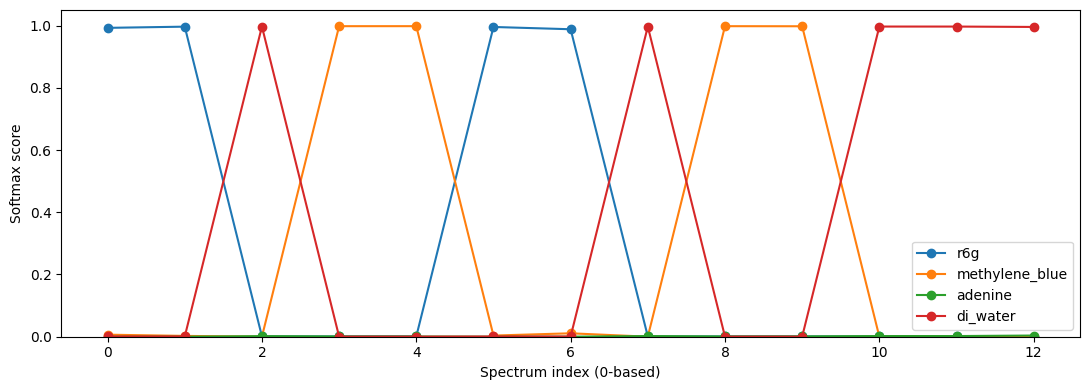

  Saved plot: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\pure_only_20260923\pure_softmax_v4\results\vit_1d_real_file_avg_probabilities.png


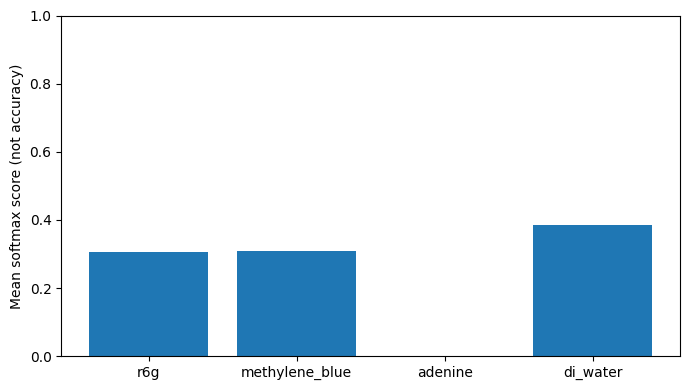


  Components with at least one confident assigned point (not proof of a mixture):
    r6g                  mean_score=0.3062; assigned_spectrum_indices=[0, 1, 5, 6]
    methylene_blue       mean_score=0.3089; assigned_spectrum_indices=[3, 4, 8, 9]
  Mean scores are descriptive, not scan-wide presence decisions or accuracy.

SCAN DISTRIBUTION SUMMARY
Pure-class assignment: top-1 score >= 0.60; top-two margin >= 0.15.
Position notes: spectrum index starts at 0; point ID starts at 1.
Single-class predictions do not prove chemical purity. This model cannot validate mixtures.
di_water means a model water/background-class response, not proof of water or absence of analyte.
High softmax scores can still be wrong on new scans; compare with recorded sample positions.
This scan was inspected during development; use a new independent scan for final validation.
  r6g: indices=[0, 1, 5, 6]; point IDs=[1, 2, 6, 7]
  di_water: indices=[2, 7, 10, 11, 12]; point IDs=[3, 8, 11, 12, 13]
  methylene_blue

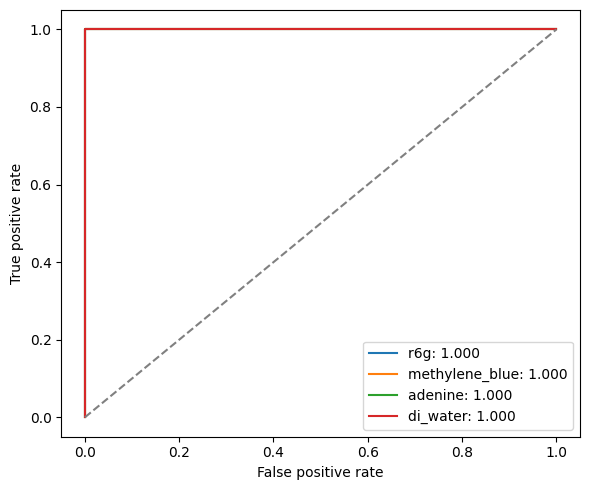

  Saved plot: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\pure_only_20260923\pure_softmax_v4\results\test_confusion_matrix.png


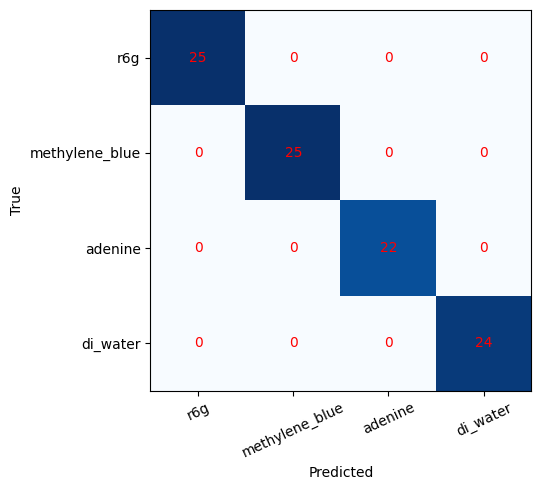

Target Macro-F1=1.0000; mixture exact-match=N/A (pure-only model)
Test accuracy=1.0000; accepted fraction=1.0000
F1 = 2 * precision * recall / (precision + recall).
Saved benchmark: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\pure_only_20260923\pure_softmax_v4\results
Saved results: C:\Users\Jeremy666\OneDrive\Documents\laser_test\build\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug\pure_only_20260923\pure_softmax_v4\results


In [3]:
"""Pure-class ViT-1D v4. No synthetic mixtures; not a mixture detector."""
import os, sys, re, json, csv, random, hashlib
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score, roc_curve

BASE = Path('C:\\Users\\Jeremy666\\OneDrive\\Documents\\laser_test\\build\\Desktop_Qt_6_6_3_MSVC2019_64bit-Debug')
DATA_DIR = BASE / 'pure_only_20260923/data_r6g_20260922'
OUTPUT_DIR = BASE / 'pure_only_20260923/pure_softmax_v4/results'
TEST_FILE = BASE / 'scan_sessions/1d_y_scan_20260921_152840_289/laser_log_combined.txt'
TEST_DARK_FILE = BASE / 'dark_measurements/dark_20260921_153016_700.txt'
# First run trains automatically. Set True only to train again.
RETRAIN_MODEL = False
SEED = 42
EPOCHS = 100
PATIENCE = 25
LR = 0.0002
BATCH_SIZE = 32
# This is a rejection setting, not a calibrated probability guarantee.
MIN_CONFIDENCE = 0.60
MIN_MARGIN = 0.15
CLASS_NAMES = ['r6g', 'methylene_blue', 'adenine', 'di_water']
TARGET_LEN = 2048
TARGET_LEN_RAW = 2048
DROP_N = 90
DO_BASELINE = True
BASELINE_WINDOW = BASELINE_SMOOTH = 15
PATCH_SIZE = 64
D_MODEL = 128
NUM_HEADS = 4
DEPTH = 4
MLP_RATIO = 4.0
NUM_CLASSES = 4
DROPOUT = 0.15
ATTN_DROP = DROP_PATH = 0.10
ERROR_PHRASE = 'image data error code 0x0001'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(2)


def strip_prefix(line):
    line=line.strip(); line=re.sub(r"^\[[^\]]+\]\s+\[Backend\]\s*","",line); line=re.sub(r"^\[[^\]]+\]\s*","",line); return line.strip()

def load_dark_spectrum_from_file(dark_path):
    if not dark_path or not Path(dark_path).exists(): return np.array([],dtype=np.float64)
    intensities=[]
    with open(dark_path,"r",encoding="utf-8",errors="ignore") as f:
        for line in f:
            line=line.strip()
            if not line or line.startswith("#") or line.startswith("index"): continue
            parts=line.split("\t")
            if len(parts)>=3:
                try: intensities.append(float(parts[2]))
                except: continue
    return np.array(intensities,dtype=np.float64)

def parse_portable_log_to_spectra(log_file):
    with open(
        log_file,
        "r",
        encoding="utf-8-sig",
        errors="ignore"
    ) as f:
        lines = f.read().splitlines()

    spectra = []
    failed = 0
    i = 0

    error_phrase = str(ERROR_PHRASE).lower()

    # Match lines containing only hex values.
    hex_line_pattern = re.compile(
        r"[0-9A-Fa-f]{2,4}(?:\s+[0-9A-Fa-f]{2,4})*"
    )

    while i < len(lines):
        line_raw = lines[i]
        line = strip_prefix(line_raw).strip()

        # Skip blank lines and comments.
        if not line or line.startswith("#"):
            i += 1
            continue

        if error_phrase and error_phrase in line_raw.lower():
            failed += 1
            i += 1
            continue

        # Find the next spectrum.
        if not line.startswith("Image Data"):
            i += 1
            continue

        payload = line[len("Image Data"):].strip()
        tokens = []
        block_err = False

        if payload:
            if hex_line_pattern.fullmatch(payload):
                tokens.extend(payload.split())
            else:
                block_err = True

        j = i + 1

        # Read any continuation lines.
        while j < len(lines):
            nxt_raw = lines[j]
            nxt = strip_prefix(nxt_raw).strip()

            # Keep the next spectrum for the outer loop.
            if nxt.startswith("Image Data"):
                break

            if nxt.startswith("Stop Capture"):
                break

            if not nxt or nxt.startswith("#"):
                j += 1
                continue

            if error_phrase and error_phrase in nxt_raw.lower():
                block_err = True

            # Ignore non-data lines.
            if hex_line_pattern.fullmatch(nxt):
                tokens.extend(nxt.split())

            j += 1

        if block_err or not tokens:
            failed += 1
        else:
            vals = np.array(
                [int(token, 16) for token in tokens],
                dtype=np.int64
            )

            # Keep legacy byte-pair conversion.
            if vals.size % 2 == 0 and vals.max(initial=0) <= 255:
                le = vals[0::2] + (vals[1::2] << 8)
                be = (vals[0::2] << 8) + vals[1::2]

                if le.max(initial=0) >= be.max(initial=0):
                    v16 = le
                else:
                    v16 = be

                if v16.max(initial=0) > 255:
                    vals = v16.astype(np.int64)

            spectra.append(vals.astype(np.float64))

        # Advance without skipping the next spectrum.
        i = j

    return spectra, failed

def moving_average(y,w):
    w=int(max(3,w));
    if w%2==0: w+=1
    p=w//2; yp=np.pad(y,(p,p),mode="edge")
    return np.convolve(yp,np.ones(w,dtype=np.float64)/w,mode="valid")

def rolling_minimum(y,w):
    w=int(max(3,w))
    if w%2==0: w+=1
    p=w//2; yp=np.pad(y,(p,p),mode="edge")
    out=np.empty_like(y,dtype=np.float64)
    for i in range(y.size): out[i]=np.min(yp[i:i+w])
    return out

def baseline_correction_fast(y,window=15,smooth=15):
    y=np.asarray(y,dtype=np.float64)
    if y.size<5: return y.copy()
    return y-moving_average(rolling_minimum(y,window),smooth)

def normalize_min_max(y):
    y=np.asarray(y,dtype=np.float64); mn,mx=y.min(),y.max(); d=mx-mn
    return np.zeros_like(y) if d<1e-12 else (y-mn)/d

def pad_or_trim(x,tgt):
    x=np.asarray(x,dtype=np.float32)
    if x.size==tgt: return x
    if x.size>tgt: return x[:tgt]
    out=np.zeros(tgt,dtype=np.float32); out[:x.size]=x; return out

def preprocess_two_versions(raw_spectrum,dark_raw):
    s=np.asarray(raw_spectrum,np.float64)
    if s.size<TARGET_LEN_RAW: return None,None,None
    s2048=s[:TARGET_LEN_RAW]
    d2048=dark_raw[:TARGET_LEN_RAW] if dark_raw.size>=TARGET_LEN_RAW else dark_raw
    raw_dark=s2048-d2048 if d2048.size>=TARGET_LEN_RAW else s2048.copy()
    if DROP_N>=raw_dark.size: return None,None,None
    raw_dark=raw_dark[DROP_N:]
    quality={"ptp":float(np.ptp(raw_dark)),"std":float(np.std(raw_dark))}
    bl=baseline_correction_fast(raw_dark,BASELINE_WINDOW,BASELINE_SMOOTH) if DO_BASELINE else raw_dark.copy()
    mm=normalize_min_max(bl).astype(np.float32)
    mm_padded=pad_or_trim(mm,TARGET_LEN)
    return bl.astype(np.float32),mm_padded,quality

class DropPath(nn.Module):
    def __init__(self,p=0.0): super().__init__(); self.p=p
    def forward(self,x):
        if self.p==0.0 or not self.training: return x
        keep=1.0-self.p; mask=torch.floor(torch.rand((x.shape[0],)+(1,)*(x.ndim-1),dtype=x.dtype,device=x.device)+keep)
        return x*mask/keep

class PatchEmbedding1D(nn.Module):
    def __init__(self,seq_len,patch_size,d_model):
        super().__init__()
        assert seq_len%patch_size==0
        self.patch_size=patch_size; self.num_patches=seq_len//patch_size
        self.proj=nn.Linear(patch_size,d_model,bias=False); self.norm=nn.LayerNorm(d_model)
    def forward(self,x):
        B,L=x.shape; return self.norm(self.proj(x.view(B,self.num_patches,self.patch_size)))

class MultiHeadSelfAttention(nn.Module):
    def __init__(self,d_model,num_heads,attn_drop=0.0):
        super().__init__()
        assert d_model%num_heads==0
        self.num_heads=num_heads; self.head_dim=d_model//num_heads; self.scale=self.head_dim**-0.5
        self.qkv=nn.Linear(d_model,d_model*3,bias=False); self.proj=nn.Linear(d_model,d_model,bias=False)
        self.attn_drop=nn.Dropout(attn_drop)
    def forward(self,x):
        B,N,C=x.shape
        qkv=self.qkv(x).reshape(B,N,3,self.num_heads,self.head_dim).permute(2,0,3,1,4)
        q,k,v=qkv.unbind(0)
        attn=self.attn_drop((q@k.transpose(-2,-1)*self.scale).softmax(dim=-1))
        return self.proj((attn@v).transpose(1,2).reshape(B,N,C))

class TransformerBlock(nn.Module):
    def __init__(self,d_model,num_heads,mlp_ratio=4.0,dropout=0.0,attn_drop=0.0,drop_path=0.0):
        super().__init__()
        self.norm1=nn.LayerNorm(d_model); self.attn=MultiHeadSelfAttention(d_model,num_heads,attn_drop)
        self.dp1=DropPath(drop_path); self.norm2=nn.LayerNorm(d_model)
        h=int(d_model*mlp_ratio)
        self.ffn=nn.Sequential(nn.Linear(d_model,h),nn.GELU(),nn.Dropout(dropout),nn.Linear(h,d_model),nn.Dropout(dropout))
        self.dp2=DropPath(drop_path)
    def forward(self,x):
        x=x+self.dp1(self.attn(self.norm1(x))); return x+self.dp2(self.ffn(self.norm2(x)))

class RamanViT1D(nn.Module):
    def __init__(self,seq_len=TARGET_LEN,patch_size=PATCH_SIZE,d_model=D_MODEL,
                 num_heads=NUM_HEADS,depth=DEPTH,mlp_ratio=MLP_RATIO,
                 num_classes=NUM_CLASSES,dropout=DROPOUT,attn_drop=ATTN_DROP,drop_path=DROP_PATH):
        super().__init__(); self.d_model=d_model
        self.patch_embed=PatchEmbedding1D(seq_len,patch_size,d_model)
        np_=seq_len//patch_size
        self.cls_token=nn.Parameter(torch.zeros(1,1,d_model))
        self.pos_embed=nn.Parameter(torch.zeros(1,np_+1,d_model))
        self.pos_drop=nn.Dropout(dropout)
        dpr=[x.item() for x in torch.linspace(0,drop_path,depth)]
        self.blocks=nn.ModuleList([TransformerBlock(d_model,num_heads,mlp_ratio,dropout,attn_drop,dpr[i]) for i in range(depth)])
        self.norm=nn.LayerNorm(d_model)
        self.head=nn.Sequential(nn.Linear(d_model,64),nn.GELU(),nn.Dropout(dropout),nn.Linear(64,num_classes))
        self._init_weights()
    def _init_weights(self):
        nn.init.trunc_normal_(self.pos_embed,std=0.02); nn.init.trunc_normal_(self.cls_token,std=0.02)
        for m in self.modules():
            if isinstance(m,nn.Linear):
                nn.init.trunc_normal_(m.weight,std=0.02)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m,nn.LayerNorm): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward_embedding(self,x):
        B=x.shape[0]; x=self.patch_embed(x)
        x=torch.cat([self.cls_token.expand(B,-1,-1),x],dim=1)+self.pos_embed
        x=self.pos_drop(x)
        for blk in self.blocks: x=blk(x)
        return self.norm(x)[:,0]
    def forward(self,x):
        emb=self.forward_embedding(x); return self.head(emb),emb

def write_csv(path, rows):
    if not rows:
        return
    with open(path, 'w', newline='', encoding='utf-8-sig') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)


class PureDataset(Dataset):
    def __init__(self, x, y, axis, augment=False):
        self.x, self.y, self.axis, self.augment = x, y, axis, augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        x = self.x[index].copy()
        if self.augment:
            n = len(self.axis)
            delta = np.random.uniform(-8.0, 8.0)
            shifted = np.interp(self.axis + delta, self.axis, x[:n])
            x[:n] = normalize_min_max(shifted)
        return torch.from_numpy(x), torch.tensor(self.y[index], dtype=torch.long)


def probabilities(model, x):
    model.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            logits, _ = model(torch.tensor(x[start:start+BATCH_SIZE], device=DEVICE))
            out.append(logits.softmax(dim=1).cpu().numpy())
    return np.concatenate(out)


def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / name, dpi=180)
    print(f'  Saved plot: {OUTPUT_DIR / name}')
    if 'ipykernel' in sys.modules:
        plt.show()
    plt.close()


def benchmark(model, x, y):
    print('\n' + '=' * 70)
    print('MODEL-NATIVE HELD-OUT TEST REPORT (spectrum-level split)')
    print('Decision: softmax top-1; rejection coverage reported separately.')
    p = probabilities(model, x)
    pred = p.argmax(1)
    prec, rec, f1, support = precision_recall_fscore_support(y, pred, labels=range(4), zero_division=0)
    rows = []
    plt.figure(figsize=(6, 5))
    for k, name in enumerate(CLASS_NAMES):
        true, positive = y == k, pred == k
        auc = roc_auc_score(true, p[:, k])
        row = dict(target=name, TP=int((true & positive).sum()), FP=int((~true & positive).sum()),
                   FN=int((true & ~positive).sum()), TN=int((~true & ~positive).sum()),
                   precision=float(prec[k]), recall=float(rec[k]), f1=float(f1[k]), roc_auc=float(auc), support=int(support[k]))
        rows.append(row)
        print(f"[{name:20s}] TP={row['TP']} FP={row['FP']} FN={row['FN']} TN={row['TN']}")
        print(f'  Precision={prec[k]:.4f} Recall={rec[k]:.4f} F1={f1[k]:.4f} ROC-AUC={auc:.4f}')
        a, b, _ = roc_curve(true, p[:, k])
        plt.plot(a, b, label=f'{name}: {auc:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend()
    save_plot('test_roc.png')
    cm = confusion_matrix(y, pred, labels=range(4))
    plt.figure(figsize=(7, 5)); plt.imshow(cm, cmap='Blues')
    for i in range(4):
        for j in range(4):
            plt.text(j, i, str(cm[i, j]), ha='center', va='center', color='red')
    plt.xticks(range(4), CLASS_NAMES, rotation=25); plt.yticks(range(4), CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('True'); save_plot('test_confusion_matrix.png')
    sorted_p = np.sort(p, axis=1)
    accepted = (sorted_p[:, -1] >= MIN_CONFIDENCE) & ((sorted_p[:, -1]-sorted_p[:, -2]) >= MIN_MARGIN)
    overall = dict(model='ViT-1D pure softmax v4', test_count=len(y), target_macro_f1=float(f1[:3].mean()),
                   accuracy=float((y == pred).mean()), accepted_fraction=float(accepted.mean()),
                   accepted_accuracy=float((y[accepted] == pred[accepted]).mean()) if accepted.any() else None,
                   mixture_exact_match='N/A: pure-only model/data', selection='minimum validation cross-entropy')
    write_csv(OUTPUT_DIR / 'per_target_metrics.csv', rows)
    write_csv(OUTPUT_DIR / 'overall_metrics.csv', [overall])
    write_csv(OUTPUT_DIR / 'test_predictions.csv', [dict(index=i, true=CLASS_NAMES[int(y[i])], predicted=CLASS_NAMES[int(pred[i])],
              **{name: float(p[i, k]) for k, name in enumerate(CLASS_NAMES)}) for i in range(len(y))])
    print(f"Target Macro-F1={overall['target_macro_f1']:.4f}; mixture exact-match=N/A (pure-only model)")
    print(f"Test accuracy={overall['accuracy']:.4f}; accepted fraction={overall['accepted_fraction']:.4f}")
    print('F1 = 2 * precision * recall / (precision + recall).')
    print('WARNING: spectrum-level split; not independent acquisition-batch validation.')
    print('Saved benchmark:', OUTPUT_DIR)


def scan(model):
    print('\n' + '=' * 70); print('Inference'); print('=' * 70)
    raw, failed = parse_portable_log_to_spectra(TEST_FILE)
    print(f'  Parsed: {len(raw)} spectra, {failed} failed')
    dark = load_dark_spectrum_from_file(TEST_DARK_FILE)
    if dark.size != 2048 or not np.isfinite(dark).all():
        raise ValueError('A complete finite 2048-pixel dark spectrum is required.')
    rows, features, ids = [], [], []
    for i, s in enumerate(raw):
        row = dict(spectrum_index=i, point_id=i+1, y_mm='', label='REJECTED', reason='',
                   r6g='', methylene_blue='', adenine='', di_water='')
        sidecar = TEST_FILE.parent / f'point_{i+1:04d}.json'
        if sidecar.exists():
            meta = json.loads(sidecar.read_text(encoding='utf-8-sig'))
            # Coordinates are used only when the sidecar spectrum matches.
            if np.array_equal(np.asarray(meta.get('intensity', [])), s):
                row['y_mm'] = meta['controller_y_steps'] / 34700.0
        if s.size != 2048 or not np.isfinite(s).all() or np.any(s >= 65535):
            row['reason'] = 'Incomplete, nonfinite, or saturated spectrum'
        else:
            _, mm, quality = preprocess_two_versions(s, dark)
            if quality['ptp'] < 100 or quality['std'] < 15:
                row['reason'] = 'Low raw signal'
            else:
                features.append(mm); ids.append(i)
        rows.append(row)
    if features:
        p = probabilities(model, np.stack(features))
        for j, i in enumerate(ids):
            order = np.argsort(p[j]); k = order[-1]
            row = rows[i]
            row.update({name: float(p[j, c]) for c, name in enumerate(CLASS_NAMES)})
            row['label'] = CLASS_NAMES[k] if p[j, k] >= MIN_CONFIDENCE and p[j, k]-p[j, order[-2]] >= MIN_MARGIN else 'UNKNOWN'
            row['reason'] = 'Low confidence or small top-two margin' if row['label'] == 'UNKNOWN' else ''
            scores_text = '  '.join(f'{name}={p[j, c]:.3f}' for c, name in enumerate(CLASS_NAMES))
            print(f'  [SPEC {i:3d}] [{scores_text}]')
        print('\n' + '=' * 70); print('SCAN COMPONENT SUMMARY (ViT-1D average scores)'); print('=' * 70)
        print(f'  Accepted: {len(ids)}; rejected by input quality: {len(raw)-len(ids)}')
        print(f'\n  === ViT-1D softmax scores (avg over {len(ids)} spectra) ===')
        for k, name in enumerate(CLASS_NAMES):
            print(f'    {name:20s} {p[:, k].mean():.4f}')
        plt.figure(figsize=(11, 4))
        for k, name in enumerate(CLASS_NAMES):
            plt.plot(ids, p[:, k], marker='o', label=name)
        plt.xlabel('Spectrum index (0-based)'); plt.ylabel('Softmax score'); plt.ylim(0, 1.05); plt.legend()
        save_plot('vit_1d_real_file_probabilities.png')
        plt.figure(figsize=(7, 4)); plt.bar(CLASS_NAMES, p.mean(0))
        plt.ylabel('Mean softmax score (not accuracy)'); plt.ylim(0, 1)
        save_plot('vit_1d_real_file_avg_probabilities.png')
        print('\n  Components with at least one confident assigned point (not proof of a mixture):')
        for k, name in enumerate(CLASS_NAMES[:3]):
            indices = [r['spectrum_index'] for r in rows if r['label'] == name]
            if indices:
                print(f'    {name:20s} mean_score={p[:, k].mean():.4f}; assigned_spectrum_indices={indices}')
        print('  Mean scores are descriptive, not scan-wide presence decisions or accuracy.')
        print('=' * 70)
    else:
        print('  >>> RESULT: UNKNOWN (no accepted spectra)')
    write_csv(OUTPUT_DIR / 'scan_point_predictions.csv', rows)
    lines = ['', '=' * 70, 'SCAN DISTRIBUTION SUMMARY',
             f'Pure-class assignment: top-1 score >= {MIN_CONFIDENCE:.2f}; top-two margin >= {MIN_MARGIN:.2f}.',
             'Position notes: spectrum index starts at 0; point ID starts at 1.',
             'Single-class predictions do not prove chemical purity. This model cannot validate mixtures.',
             'di_water means a model water/background-class response, not proof of water or absence of analyte.',
             'High softmax scores can still be wrong on new scans; compare with recorded sample positions.',
             'This scan was inspected during development; use a new independent scan for final validation.']
    for label in dict.fromkeys(r['label'] for r in rows):
        group = [r for r in rows if r['label'] == label]
        lines.append(f"  {label}: indices={[r['spectrum_index'] for r in group]}; point IDs={[r['point_id'] for r in group]}")
    lines.append('Point details:')
    for row in rows:
        position = f"Y={row['y_mm']:.3f} mm" if row['y_mm'] != '' else 'Position not verified'
        lines.append(f"  Index {row['spectrum_index']:02d} / point {row['point_id']:02d}: {position}; {row['label']}; {row['reason']}")
    lines.append('=' * 70)
    (OUTPUT_DIR / 'spatial_summary.txt').write_text('\n'.join(lines), encoding='utf-8')
    print('\n'.join(lines))
    print('Saved position notes:', OUTPUT_DIR / 'spatial_summary.txt')


def main():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    manifest = json.loads((DATA_DIR / 'manifest.json').read_text(encoding='utf-8'))
    assert manifest['classes'] == CLASS_NAMES
    for item in manifest['files']:
        if hashlib.sha256((DATA_DIR / item['name']).read_bytes()).hexdigest() != item['sha256']:
            raise ValueError('Dataset changed: ' + item['name'])
    arrays = [np.load(DATA_DIR / f'training_spectra_{c}_minmax.npy').astype(np.float32) for c in CLASS_NAMES]
    y = np.concatenate([np.full(len(a), k, dtype=np.int64) for k, a in enumerate(arrays)])
    x = np.pad(np.vstack(arrays), ((0, 0), (0, TARGET_LEN-arrays[0].shape[1])))
    assert np.isfinite(x).all()
    axis = np.load(DATA_DIR / 'raman_shift_axis_methylene_blue.npy')
    tr, va, te = [np.array(manifest['split'][s]) for s in ('train', 'val', 'test')]
    assert sorted(np.concatenate([tr, va, te]).tolist()) == list(range(len(y)))
    print(f'DEVICE={DEVICE}  RETRAIN={RETRAIN_MODEL}', flush=True)
    print('\n' + '=' * 70); print('Step 1: Load real pure spectra (synthetic mixtures disabled)'); print('=' * 70)
    for name, array in zip(CLASS_NAMES, arrays):
        print(f'  {name:20s} shape={array.shape}')
    print(f'\n  Pure={len(y)}  Synthetic=0  Total={len(y)}')
    print('\n' + '=' * 70); print('Step 2: Split'); print('=' * 70)
    print(f'  train={len(tr)} val={len(va)} test={len(te)}')
    model = RamanViT1D().to(DEVICE)
    model_path = OUTPUT_DIR / 'vit1d_pure_softmax.pt'
    if RETRAIN_MODEL or not model_path.exists():
        print('\n' + '=' * 70); print('Step 3: Training ViT-1D (pure-class softmax)'); print('=' * 70)
        loader = DataLoader(PureDataset(x[tr], y[tr], axis, True), batch_size=BATCH_SIZE, shuffle=True)
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS, eta_min=1e-5)
        criterion = nn.CrossEntropyLoss()
        best, bad, history = float('inf'), 0, []
        for epoch in range(1, EPOCHS+1):
            model.train(); total = 0.0
            for bx, by in loader:
                bx, by = bx.to(DEVICE), by.to(DEVICE)
                optimizer.zero_grad(); logits, _ = model(bx); loss = criterion(logits, by)
                if not torch.isfinite(loss):
                    raise RuntimeError('Nonfinite training loss')
                loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 3.0); optimizer.step()
                total += loss.item()*len(by)
            scheduler.step()
            pv = probabilities(model, x[va])
            val_loss = float(-np.log(np.maximum(pv[np.arange(len(va)), y[va]], 1e-12)).mean())
            entry = dict(epoch=epoch, train_loss=total/len(tr), val_loss=val_loss, val_accuracy=float((pv.argmax(1) == y[va]).mean()))
            history.append(entry)
            if val_loss < best-1e-6:
                best, bad = val_loss, 0
                torch.save(model.state_dict(), model_path)
                (OUTPUT_DIR / 'best_epoch.json').write_text(json.dumps(entry, indent=2), encoding='utf-8')
            else:
                bad += 1
            if epoch == 1 or epoch % 5 == 0:
                print(f'epoch {epoch:02d}/{EPOCHS} loss={total/len(tr):.4f} val_loss={val_loss:.4f} val_accuracy={entry["val_accuracy"]:.4f}', flush=True)
            if bad >= PATIENCE:
                break
        write_csv(OUTPUT_DIR / 'training_history.csv', history)
        print('Training complete; restoring minimum-validation-loss weights.', flush=True)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE, weights_only=True))
    print(f'\nTest: {TEST_FILE}')
    print(f'Dark: {TEST_DARK_FILE}')
    print(f'Loaded: {model_path}')
    provenance = dict(manifest=manifest, seed=SEED, training='CrossEntropyLoss; four pure classes',
                      augmentation='training only, symmetric +/-8 cm^-1 shift',
                      source_file=str(TEST_FILE), dark_file=str(TEST_DARK_FILE),
                      warning='Spectrum-level database split is not independent-batch validation. Not a mixture detector.')
    (OUTPUT_DIR / 'run_manifest.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
    scan(model)
    benchmark(model, x[te], y[te])
    print('Saved results:', OUTPUT_DIR)


if __name__ == '__main__':
    main()
